In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

# Get the current working directory
cwd = os.getcwd()

print(cwd)

/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008


In [3]:
df = pd.read_csv("data/raw/diabetic_data.csv",
                 keep_default_na=False,
                 na_values=["?"],
                 dtype={"payer_code": "str"})

## replace '?" with NA
#df = df.replace("?", pd.NA)

In [4]:
df.shape

(101766, 50)

In [5]:
len(df)

101766

In [6]:
df.shape[1]

50

In [7]:
str_cols = df.select_dtypes(include=['str']).columns
str_cols = str_cols[ ~str_cols.isin( ['age', 'weight' ] ) ]
df[str_cols] = df[str_cols].astype('category')

In [8]:
df["weight"].unique()

<StringArray>
[        nan,  '[75-100)',   '[50-75)',    '[0-25)', '[100-125)',   '[25-50)',
 '[125-150)', '[175-200)', '[150-175)',      '>200']
Length: 10, dtype: str

In [9]:
df["weight"].unique()

<StringArray>
[        nan,  '[75-100)',   '[50-75)',    '[0-25)', '[100-125)',   '[25-50)',
 '[125-150)', '[175-200)', '[150-175)',      '>200']
Length: 10, dtype: str

In [10]:
## now set the order of some of the variables
age_order = [  '[0-10)',  '[10-20)',  '[20-30)',  '[30-40)',  '[40-50)',  '[50-60)',
  '[60-70)',  '[70-80)',  '[80-90)', '[90-100)']

age_type = pd.CategoricalDtype( categories=age_order,
                                ordered=True )
df["age"] = df["age"].astype(age_type)

weight_order = [ "[0-25)", "[25-50)", "[50-75)", "[75-100)",
                 "[100-125)", "[125-150)", "[150-175)",
                 "[175-200)", ">200" ]
weight_type = pd.CategoricalDtype( categories=weight_order,
                                   ordered=True )
df["weight"] = df["weight"].astype(weight_type)

In [11]:
# Returns an Index of column names containing '_id'
id_cols = df.columns[df.columns.str.contains('_id')]
id_cols = id_cols[ ~id_cols.isin( ["encounter_id"] ) ]
id_cols
df[ id_cols ] = df[ id_cols] .astype('category')

In [12]:
print( type( id_cols ))

<class 'pandas.Index'>


In [13]:
print(type(str_cols) )

<class 'pandas.Index'>


In [14]:
cat_cols = id_cols.append( str_cols )

## Patient-level versus encounter-level analysis

In [15]:
df2 = df.groupby("patient_nbr").agg(
    n_encounters=("encounter_id", "size"),
    n_early_readmissions=("readmitted", lambda x: (x == "<30").sum()),
    n_later_readmissions=("readmitted", lambda x: (x == ">30").sum()),
    n_all_readmissions=("readmitted", lambda x: (x != "NO").sum()),
    n_no_readmissions=("readmitted", lambda x: (x == "NO").sum()),
    mean_lab_procedures=( "num_lab_procedures", "mean" ),
    mean_procedures=( "num_procedures", "mean" ),
    mean_medications=( "num_medications", "mean" ),
    mean_outpatient=( "number_outpatient", "mean" ),
    mean_inpatient=( "number_inpatient", "mean" ),
    mean_emergency=( "number_emergency", "mean" ) )
    

In [16]:
df2.head().transpose()

patient_nbr,135,378,729,774,927
n_encounters,2.0,1.0,1.0,1.0,1.0
n_early_readmissions,1.0,0.0,0.0,0.0,0.0
n_later_readmissions,1.0,0.0,0.0,0.0,0.0
n_all_readmissions,2.0,0.0,0.0,0.0,0.0
n_no_readmissions,0.0,1.0,1.0,1.0,1.0
mean_lab_procedures,54.0,49.0,68.0,46.0,49.0
mean_procedures,3.5,1.0,2.0,0.0,0.0
mean_medications,23.5,11.0,23.0,20.0,5.0
mean_outpatient,0.0,0.0,0.0,0.0,0.0
mean_inpatient,0.5,0.0,0.0,0.0,0.0


In [17]:
df2.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
n_encounters,71518.0,1.422942,1.090740,1.0,1.0,1.0,1.0,40.000000
n_early_readmissions,71518.0,0.158799,0.523822,0.0,0.0,0.0,0.0,23.000000
n_later_readmissions,71518.0,0.497008,0.916092,0.0,0.0,0.0,1.0,17.000000
n_all_readmissions,71518.0,0.655807,1.195101,0.0,0.0,0.0,1.0,40.000000
n_no_readmissions,71518.0,0.767136,0.424113,0.0,1.0,1.0,1.0,2.000000
mean_lab_procedures,71518.0,43.223110,18.893236,1.0,32.0,44.0,56.0,121.000000
mean_procedures,71518.0,1.412397,1.663913,0.0,0.0,1.0,2.0,6.000000
mean_medications,71518.0,15.786512,7.913624,1.0,10.0,15.0,20.0,81.000000
mean_outpatient,71518.0,0.307315,1.084458,0.0,0.0,0.0,0.0,36.000000
mean_inpatient,71518.0,0.336127,0.735060,0.0,0.0,0.0,0.5,14.125000


In [18]:
df2["n_encounters"].quantile([0.95, 0.975])

0.950    3.0
0.975    4.0
Name: n_encounters, dtype: float64

In [19]:
conditions = [
    df2["n_encounters"] == 1,
    (df2["n_encounters"] >= 2) & (df2["n_encounters"] < 6),
    df2["n_encounters"] >= 6,
]

# Define the labels for each condition
labels = ["single", "mid", "high"]

# Apply using np.select(conditions, labels, default)
df2["utilization"] = np.select(conditions, labels, default="single")


In [20]:
df2[ "utilization"].value_counts()

utilization
single    54745
mid       15900
high        873
Name: count, dtype: int64

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

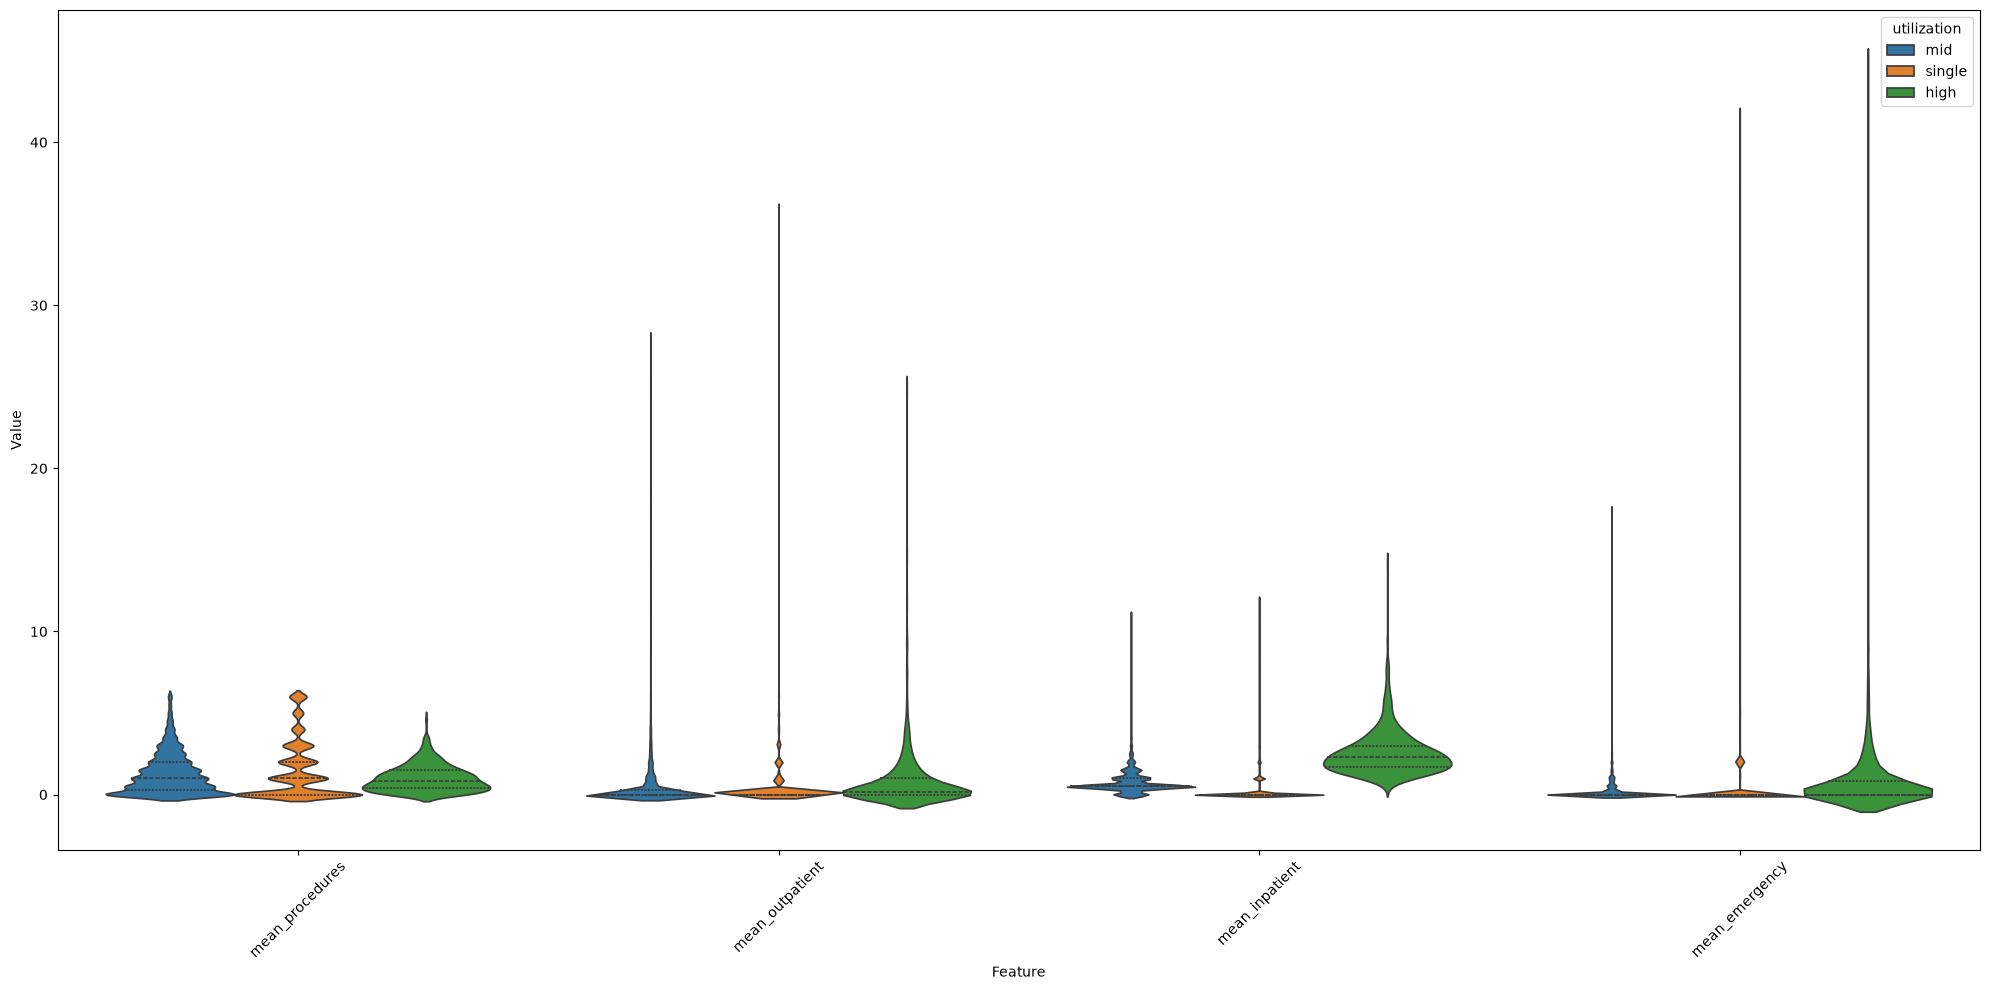

In [22]:
plt.figure(figsize=(20, 10))
cols = [
    "mean_procedures",
    "mean_outpatient",
    "mean_inpatient",
    "mean_emergency"
]

df_long = df2.melt(
    id_vars="utilization",
    value_vars=cols,
    var_name="Feature",
    value_name="Value"
)

sns.violinplot(
    data=df_long,
    x="Feature",
    y="Value",
    hue="utilization",
    density_norm="width",
    inner="quart"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
df2[ df2["utilization"] == "single" ][ "mean_emergency" ].sort_values().tail()

patient_nbr
75740436    11.0
62920269    20.0
91325448    25.0
90847035    37.0
42466248    42.0
Name: mean_emergency, dtype: float64

## Clinical and utilization patterns

In [24]:
multi_encounter_patients = list( df2[ df2[ "n_encounters"] > 1 ].index )
df[ df[ "patient_nbr" ].isin(multi_encounter_patients )].groupby("patient_nbr")[cat_cols].nunique().apply(
    lambda x: x.value_counts(normalize=True).sort_index()
).transpose().tail( 40 )

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,17
admission_type_id,NaN,0.534967,0.426459,0.037620,0.000954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
discharge_disposition_id,NaN,0.486615,0.421630,0.076134,0.013414,0.001848,0.000358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_source_id,NaN,0.577297,0.406785,0.014965,0.000835,0.000119,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,0.011745,0.980922,0.007214,0.000119,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,NaN,0.999821,0.000179,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payer_code,0.316640,0.538961,0.131163,0.012222,0.000715,0.000238,0.000060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
medical_specialty,0.408573,0.378048,0.181065,0.028200,0.003756,0.000358,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diag_1,NaN,0.125261,0.595063,0.169379,0.061587,0.027067,0.011984,0.005068,0.001669,0.001192,0.000537,0.000477,0.000298,0.000238,0.000060,0.000119,NaN
diag_2,0.000119,0.098194,0.609014,0.177607,0.065820,0.027723,0.011447,0.005068,0.002564,0.001312,0.000417,0.000298,0.000119,0.000060,0.000179,NaN,0.00006
diag_3,0.001312,0.076313,0.607643,0.180946,0.073749,0.032493,0.013355,0.006618,0.003279,0.001550,0.001133,0.000656,0.000417,0.000417,0.000060,NaN,0.00006


### Conclusions
* it appears that the medication features (e.g. acetohexamide, citoglipton, etc) primarily have a single value that is repeated across encounters.
* Other categorical values of value like insulin, change, A1Cresult have a considerable portion of encounters with secondary values.
* The diag_## codes may be less informative at a per-patient level as most of these have 2-3 unique values per patient.
* The *_id features may be less informative at a per-patient level as most of these have 2-3 unique values per patient.
* payer_code and medical_specialty also seem less informative at a per-patient level as most of these have 2-3 unique values per patient.

In [25]:
df3 = df.groupby("patient_nbr").agg(
    n_encounters=("encounter_id", "size"),
    n_early_readmissions=("readmitted", lambda x: (x == "<30").sum()),
    n_later_readmissions=("readmitted", lambda x: (x == ">30").sum()),
    n_all_readmissions=("readmitted", lambda x: (x != "NO").sum()),
    n_no_readmissions=("readmitted", lambda x: (x == "NO").sum()),
    mean_lab_procedures=( "num_lab_procedures", "mean" ),
    mean_procedures=( "num_procedures", "mean" ),
    mean_medications=( "num_medications", "mean" ),
    mean_outpatient=( "number_outpatient", "mean" ),
    mean_inpatient=( "number_inpatient", "mean" ),
    mean_emergency=( "number_emergency", "mean" ),
    max_weigth=( "weight", "max" ),
    max_age=( "age", "max" ),
    race=("race", lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA),
    gender=("gender", lambda x: x.mode().iloc[0] if not x.mode().empty else pd.NA)
)
    

In [26]:
df3[ "utilization"] = pd.cut( df3[ "n_encounters"],
                              bins=[ 0, 1, 7, np.inf ],
                              labels=[ "single", "mid", "high" ] )

In [27]:
def first_mode(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else pd.NA

exclude_cols = [ "readmitted", "race", "gender", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3", "change" ]
categorical_summary = (
    df.groupby("patient_nbr")[cat_cols[ ~cat_cols.isin( exclude_cols)]]
      .agg(first_mode)
)

In [28]:
df3 = df3.join(categorical_summary)

In [29]:
df3.head().transpose()

patient_nbr,135,378,729,774,927
n_encounters,2,1,1,1,1
n_early_readmissions,1,0,0,0,0
n_later_readmissions,1,0,0,0,0
n_all_readmissions,2,0,0,0,0
n_no_readmissions,0,1,1,1,1
mean_lab_procedures,54.0,49.0,68.0,46.0,49.0
mean_procedures,3.5,1.0,2.0,0.0,0.0
mean_medications,23.5,11.0,23.0,20.0,5.0
mean_outpatient,0.0,0.0,0.0,0.0,0.0
mean_inpatient,0.5,0.0,0.0,0.0,0.0


In [30]:
pd.crosstab( df3["utilization"],
             df3[ "insulin" ],
            normalize="columns" )

insulin,Down,No,Steady,Up
utilization,,,,
single,0.613763,0.758716,0.823803,0.824073
mid,0.377122,0.237932,0.173132,0.166694
high,0.009115,0.003352,0.003065,0.009233


In [31]:
from scipy.stats import chi2_contingency
def compare_effect( df=df3,
                    label="utilization",
                    feature="insulin",
                    norm="columns" ):

    # Counts
    table = pd.crosstab(df[label], 
                        df[feature] )

    # Proportions
    proportions = pd.crosstab( df[label],
                               df[feature],
                               normalize=norm )

    # Effect size
    chi2, p, dof, expected = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

    # display(proportions)
    #print(f"p = {p:.3e}, Chi-square ={chi2:.4e}, Cramér's V = {cramers_v:.3f}")
    return chi2, p, dof, cramers_v, feature

In [32]:
exclude_cols = [ "readmitted", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3", "change" ]
feature_effects_df = [ compare_effect( feature=col ) for col in cat_cols[ ~cat_cols.isin( exclude_cols ) ] ]    

/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


In [33]:
feature_effects_df = pd.DataFrame(
    feature_effects_df,
    columns=["chi2", "p", "dof", "cramers_v", "feature"]
)

In [34]:
max_cramer = feature_effects_df[ "cramers_v"].max()
print( max_cramer)

0.12126659691527451


## Conclusion
* The effect of the associations between the classes of patients and the different variable is pretty weak. It might be possible to generate a predictor, but there's no obvious feature.

# Day 4: Define the readmission prediction problem

In [35]:
# Define readmit_30 as a binary outcome: <30 versus >30 and NO.
df[ "readmit_30" ] = df[ "readmitted" ] == "<30"
exclude_cols = [ "readmitted", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3", "change" ]

feature_effects_df = [ compare_effect(df=df, label="readmit_30", feature=col ) for col in cat_cols[ ~cat_cols.isin( exclude_cols ) ] ]
feature_effects_df = pd.DataFrame(
    feature_effects_df,
    columns=["chi2", "p", "dof", "cramers_v", "feature"]
)

/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


In [36]:
feature_effects_df.sort_values(by='cramers_v', ascending=False)

,chi2,p,dof,cramers_v,feature
1,1582.583386,0.000000e+00,25,0.124704,discharge_disposition_id
24,190.858814,3.981889e-41,3,0.043307,insulin
30,74.669432,5.565116e-18,1,0.027088,diabetesMed
7,58.753300,1.085303e-12,3,0.024028,metformin
2,52.731562,8.341155e-06,16,0.022763,admission_source_id
6,35.789868,8.294910e-08,3,0.018753,A1Cresult
0,26.657064,3.841108e-04,7,0.016185,admission_type_id
5,15.789606,1.252352e-03,3,0.012456,max_glu_serum
8,12.028300,7.286841e-03,3,0.010872,repaglinide
13,11.508184,9.272622e-03,3,0.010634,glipizide


In [37]:
# Define readmit_30 as a binary outcome: <30 versus >30 and NO.
df[ "readmit_30_02" ] = [ "Early" if x == "<30" else "Later" for x in df[ "readmitted" ] ]

exclude_cols = [ "readmitted", "payer_code", "medical_specialty", "diag_1", "diag_2", "diag_3", "change" ]

feature_effects_df = [ compare_effect(df=df, label="readmit_30_02", feature=col ) for col in cat_cols[ ~cat_cols.isin( exclude_cols ) ] ]
feature_effects_df = pd.DataFrame(
    feature_effects_df,
    columns=["chi2", "p", "dof", "cramers_v", "feature"]
)

/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
/tmp/ipykernel_2436599/3002586350.py:18: RuntimeWarning: invalid value encountered in divide
  cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


In [38]:
feature_effects_df.sort_values(by='cramers_v', ascending=False)

,chi2,p,dof,cramers_v,feature
1,1582.583386,0.000000e+00,25,0.124704,discharge_disposition_id
24,190.858814,3.981889e-41,3,0.043307,insulin
30,74.669432,5.565116e-18,1,0.027088,diabetesMed
7,58.753300,1.085303e-12,3,0.024028,metformin
2,52.731562,8.341155e-06,16,0.022763,admission_source_id
6,35.789868,8.294910e-08,3,0.018753,A1Cresult
0,26.657064,3.841108e-04,7,0.016185,admission_type_id
5,15.789606,1.252352e-03,3,0.012456,max_glu_serum
8,12.028300,7.286841e-03,3,0.010872,repaglinide
13,11.508184,9.272622e-03,3,0.010634,glipizide


### Conclusion:
* The categorical features have little predictive value

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

def violin_compare(
    column,
    df=df,
    group="readmit_30_02",
    pairs=[("Early", "Later")]
):
    ax = sns.violinplot(
        data=df,
        x="readmit_30_02",
        y=column
    )

    annotator = Annotator(
        ax,
        pairs,
        data=df,
        x="readmit_30_02",
        y=column
    )

    annotator.configure(
        test="Mann-Whitney",
        text_format="simple",
        loc="inside"
    )

    annotator.apply_and_annotate()

    ax.set_xlabel("Readmitted")
    ax.set_ylabel(column)
    ax.set_title(f"{column} by readmission status")

    plt.show()

Later vs. Early: Mann-Whitney-Wilcoxon test two-sided, P_val:5.377e-11 U_stat=4.940e+08


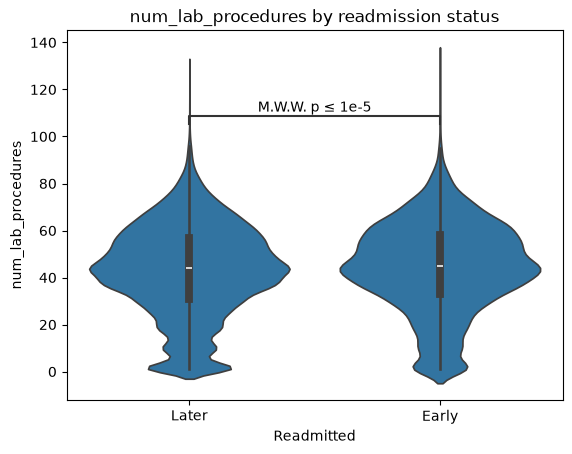

In [40]:
violin_compare( "num_lab_procedures" )

Later vs. Early: Mann-Whitney-Wilcoxon test two-sided, P_val:5.115e-02 U_stat=5.188e+08


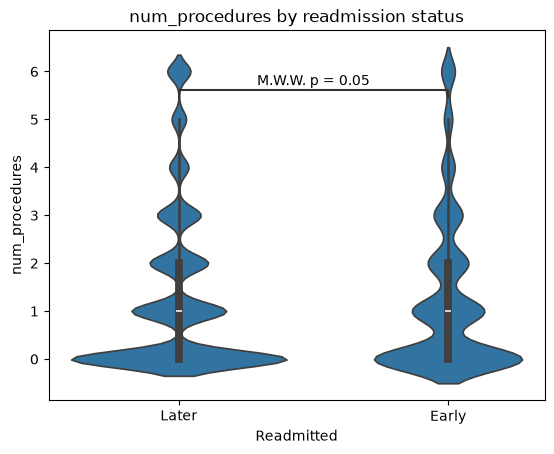

In [41]:
violin_compare( "num_procedures" )

Later vs. Early: Mann-Whitney-Wilcoxon test two-sided, P_val:1.394e-47 U_stat=4.707e+08


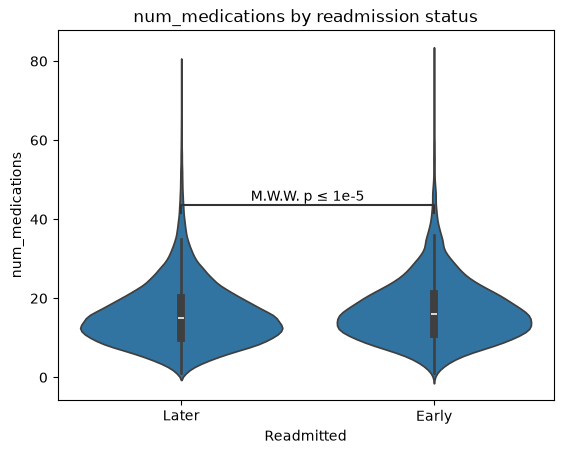

In [42]:
violin_compare( "num_medications" )

Later vs. Early: Mann-Whitney-Wilcoxon test two-sided, P_val:1.151e-27 U_stat=4.926e+08


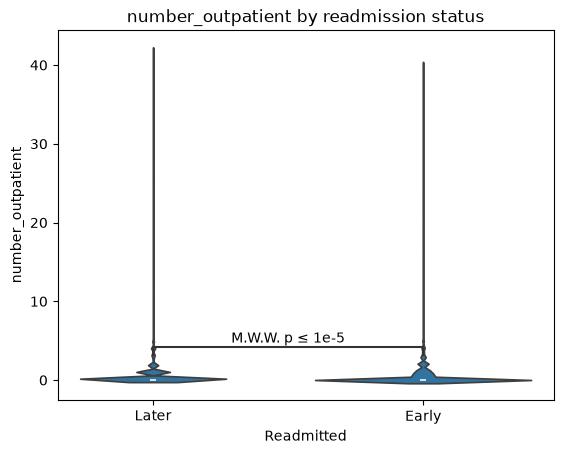

In [43]:
violin_compare( "number_outpatient" )

Later vs. Early: Mann-Whitney-Wilcoxon test two-sided, P_val:0.000e+00 U_stat=4.045e+08


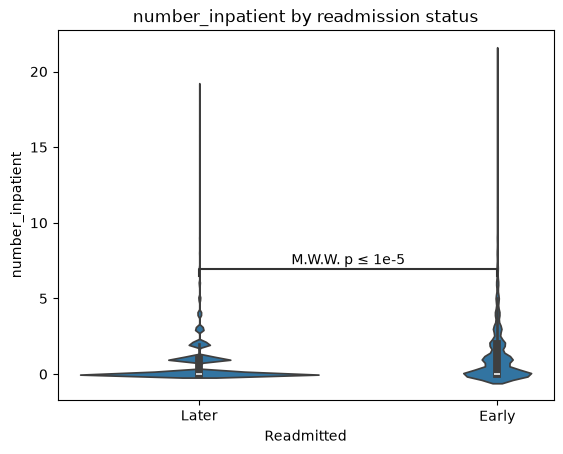

In [44]:
violin_compare( "number_inpatient" )

Later vs. Early: Mann-Whitney-Wilcoxon test two-sided, P_val:4.613e-91 U_stat=4.807e+08


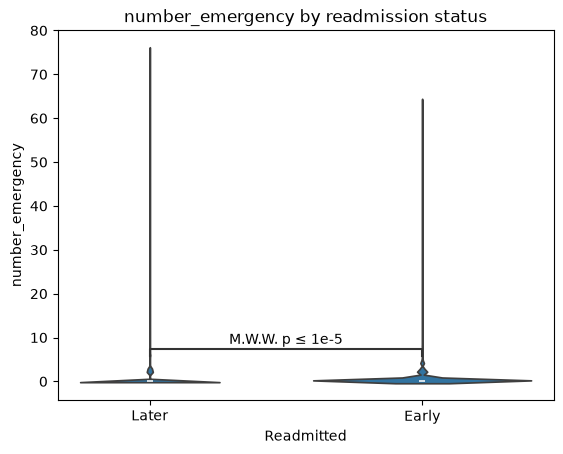

In [45]:
violin_compare( "number_emergency" )

### Conclusion:
* number_emergency & number_inpatient have obvious visual and statistical differences between the two groups.
* One needs to be careful because some of the encounters are "double counted" in these metrics, i.e. a patient that has 10+ encounters in a year will have a series of increasing values in the "number_inpatient" feature
* As discussed last week, the data should be partitioned by patient, rather than by encounter, so that we aren't splitting the records for a given patient between test and training sets.

In [47]:
df3.pivot_table(
    index="utilization",
    values=["mean_inpatient", "mean_emergency", "mean_outpatient"],
    aggfunc="mean",
    observed=True
)

,mean_emergency,mean_inpatient,mean_outpatient
utilization,,,
single,0.090529,0.171723,0.266837
mid,0.218138,0.824480,0.433315
high,0.963844,3.353080,0.753859


In [50]:
df.pivot_table(
    index="readmitted",
    columns="A1Cresult",
    values="number_inpatient",
    aggfunc="mean",
    observed=True
)

A1Cresult,>7,>8,None,Norm
readmitted,,,,
<30,0.791123,1.023428,1.284268,0.695021
>30,0.602308,0.730093,0.870533,0.642276
NO,0.259277,0.240231,0.409624,0.260227


In [63]:
pt=df.pivot_table(
    index="readmitted",
    columns="A1Cresult",
    values="number_inpatient",
    aggfunc="size",
    observed=True
)
display( pt )

A1Cresult,>7,>8,None,Norm
readmitted,,,,
<30,383,811,9681,482
>30,1300,2901,29745,1599
NO,2129,4504,45322,2909


In [62]:
normalized_cols = pt.div(pt.sum(axis=1), axis=0)
display( normalized_cols )

A1Cresult,>7,>8,None,Norm
readmitted,,,,
<30,0.033724,0.071410,0.852426,0.042441
>30,0.036573,0.081615,0.836827,0.044985
NO,0.038805,0.082094,0.826079,0.053022


In [51]:
df.pivot_table(
    index="readmitted",
    columns="A1Cresult",
    values="number_emergency",
    aggfunc="mean",
    observed=True
)

A1Cresult,>7,>8,None,Norm
readmitted,,,,
<30,0.342037,0.358816,0.359054,0.331950
>30,0.179231,0.311961,0.287073,0.253909
NO,0.069516,0.093917,0.112683,0.107941


In [55]:
df3.pivot_table(
    index="utilization",
    columns="A1Cresult",
    values="mean_inpatient",
    aggfunc="mean",
    observed=True
)

A1Cresult,>7,>8,None,Norm
utilization,,,,
single,0.110421,0.127673,0.183867,0.109163
mid,0.620962,0.691239,0.851092,0.777466
high,2.444444,3.046914,3.364900,NaN


In [56]:
df3.pivot_table(
    index="utilization",
    columns="A1Cresult",
    values="mean_inpatient",
    aggfunc="size",
    observed=True
)

A1Cresult,>7,>8,None,Norm
utilization,,,,
single,2255.0,4864.0,44603.0,3023.0
mid,811.0,1507.0,13995.0,140.0
high,1.0,9.0,310.0,NaN


## Day 5: Prepare the modeling dataset

In [67]:
labels = df[ "readmit_30_02" ]
##X = df.drop(columns=["readmit_30_02", "readmit_30", "readmitted", "patient_nbr", "encounter_id"])
features_to_model = "num_procedures number_outpatient number_emergency number_inpatient A1Cresult metformin discharge_disposition_id diabetesMed admission_source_id admission_type_id max_glu_serum".split()
X = df[ features_to_model ]

In [102]:
## from: https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector as selector

np.random.seed(0)
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selector(dtype_include=np.number)),
        ("cat", categorical_transformer, selector(dtype_include="category")),
    ]
)

In [103]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedGroupKFold

##gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(
    sgkf.split(X, labels, groups=df["patient_nbr"])
)

#for i, (train_index, test_index) in enumerate(sgkf.split(X, labels, groups)):
    ## do stuff like preprocess X


In [106]:
x_train = X.iloc[ train_idx ]
x_test = X.iloc[ test_idx ]
y_train = labels.iloc[ train_idx ]
y_test = labels.iloc[ test_idx ]

In [107]:
display( x_train.shape )
display( x_test.shape )

(81412, 11)

(20354, 11)

In [108]:
display( y_train.value_counts(normalize=True) )
display( y_test.value_counts( normalize=True) )

readmit_30_02
Later    0.888407
Early    0.111593
Name: proportion, dtype: float64

readmit_30_02
Later    0.888376
Early    0.111624
Name: proportion, dtype: float64